# Practical Assignment 6: Clustering Algorithms

Name: Parth Nandkishor Shingane

PRN: 202401040210

Roll no:51
Div: A

Batch: A2

Github link: 

## Title

**Grouping wines by their chemical properties using K-Means, Hierarchical Clustering, DBSCAN and Gaussian Mixture**

## Aim
To apply different clustering algorithms on a real-world dataset (the Wine dataset), find natural groups in it, and check how good those groups are using the Silhouette score, the Davies-Bouldin index and plots.

## Experiment Objectives
1. To understand how clustering finds groups in data that has no labels.
2. To clean and scale the data so that distance-based methods work properly.
3. To implement four algorithms: K-Means, Agglomerative (Ward), DBSCAN and Gaussian Mixture Model (GMM).
4. To pick the number of clusters using evidence (elbow, silhouette, Davies-Bouldin, BIC) instead of guessing.
5. To compare the algorithms using proper metrics and to explain which one suits this data best.

## Experiment Outcomes
After this experiment I should be able to:
- Choose a suitable clustering method for a dataset and explain why.
- Measure cluster quality with Silhouette, Davies-Bouldin, Calinski-Harabasz and Adjusted Rand Index.
- Compare the methods, explain the clusters in simple terms and suggest improvements.

## Conceptual Background

**Clustering** means putting similar items in the same group and different items in different groups, without being told the right answer beforehand.

| Algorithm | How it works (simple idea) | Main setting | Good at | Not good at |
|---|---|---|---|---|
| K-Means | Picks k centres and keeps moving them until each point is close to its centre | k | Fast and easy | Round, similar-sized groups only |
| Agglomerative (Ward) | Starts with every point alone, then keeps joining the two closest groups | k | Gives a dendrogram (tree) | Slow on very big data |
| DBSCAN | Groups points that are packed closely together, and calls lonely points "noise" | eps, min_samples | Odd shapes, finds outliers | Data where density changes, many features |
| Gaussian Mixture | Assumes data comes from a few bell-curve shapes and gives each point a probability for each group | number of components | Oval-shaped groups | Can depend on the starting guess |

**Metrics used**
- **Silhouette score** (-1 to 1): how well a point fits its own cluster compared to the nearest other cluster. Higher is better.
- **Davies-Bouldin index** (0 and above): how much clusters overlap. Lower is better.
- **Calinski-Harabasz index**: spread between clusters divided by spread inside clusters. Higher is better.
- **Adjusted Rand Index (ARI)**: how closely our clusters match the real wine types. 1 is perfect, near 0 is random. We use this only to check our work, not to train.

## Flowchart

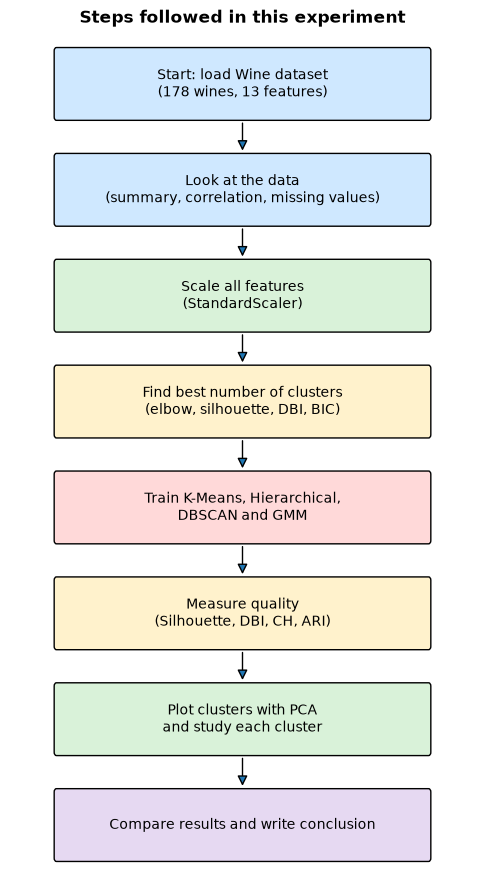

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

boxes = [
    ("Start: load Wine dataset\n(178 wines, 13 features)", "#cfe8ff"),
    ("Look at the data\n(summary, correlation, missing values)", "#cfe8ff"),
    ("Scale all features\n(StandardScaler)", "#d9f2d9"),
    ("Find best number of clusters\n(elbow, silhouette, DBI, BIC)", "#fff2cc"),
    ("Train K-Means, Hierarchical,\nDBSCAN and GMM", "#ffd9d9"),
    ("Measure quality\n(Silhouette, DBI, CH, ARI)", "#fff2cc"),
    ("Plot clusters with PCA\nand study each cluster", "#d9f2d9"),
    ("Compare results and write conclusion", "#e6d9f2"),
]
gap = 1.6
fig, ax = plt.subplots(figsize=(6, 11))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, len(boxes) * gap)
for i, (text, colour) in enumerate(boxes):
    y = (len(boxes) - 1 - i) * gap + 0.3
    ax.add_patch(FancyBboxPatch((1, y), 8, 1.0, boxstyle="round,pad=0.05", fc=colour, ec="black"))
    ax.text(5, y + 0.5, text, ha="center", va="center", fontsize=10)
    if i < len(boxes) - 1:
        ax.add_patch(FancyArrowPatch((5, y - 0.05), (5, y - 0.55), arrowstyle="-|>", mutation_scale=15))
ax.set_title("Steps followed in this experiment", fontsize=12, weight="bold")
plt.show()

## Code Implementation
### Step 1: Import libraries and load the data
The Wine dataset has chemical test results of 178 wines made from 3 grape types. The grape type column is kept aside and used **only at the end** to check our clusters. The algorithms never see it.

In [2]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
SEED = 42
sns.set_theme(style="whitegrid")

raw = load_wine(as_frame=True).frame
grape_type = raw["target"].values        # kept aside, only for checking at the end
data = raw.drop(columns="target")

print("Rows, columns :", data.shape)
print("Missing values:", int(data.isna().sum().sum()))
data.head()

Rows, columns : (178, 13)
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Step 2: Look at the data

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


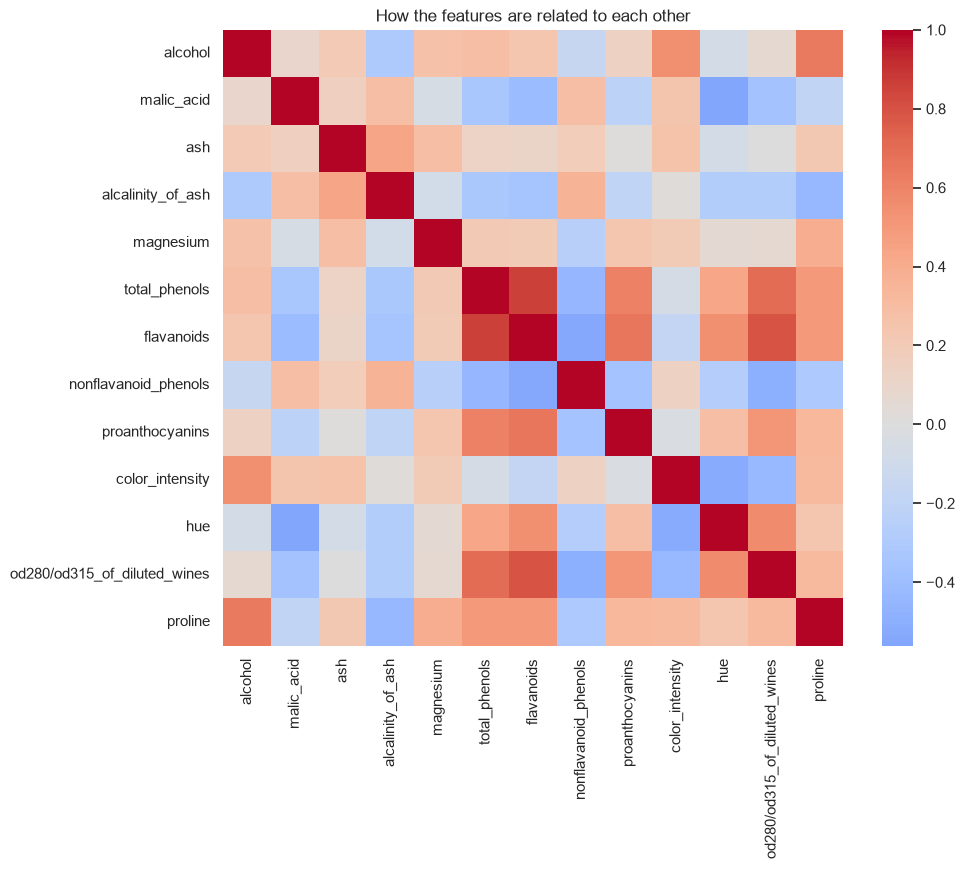

In [3]:
display(data.describe().T.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), cmap="coolwarm", center=0)
plt.title("How the features are related to each other")
plt.show()

There are no missing values. Some features are strongly related (for example *flavanoids* and *total_phenols*). Also the features are on very different scales: *proline* goes up to about 1700, while *hue* is around 1.

### Step 3: Scale the data
K-Means, hierarchical clustering and DBSCAN use distance. If we do not scale, *proline* (big numbers) will control the distance and other features will hardly matter. So we scale every feature to mean 0 and standard deviation 1.

PCA is used only to draw the data on a 2-D plot. Clustering is done on all 13 scaled features.

In [4]:
scaled = StandardScaler().fit_transform(data)

pca2 = PCA(n_components=2, random_state=SEED)
plot_xy = pca2.fit_transform(scaled)
print(f"The 2 PCA axes keep {pca2.explained_variance_ratio_.sum() * 100:.1f}% of the information")

The 2 PCA axes keep 55.4% of the information


### Step 4: Decide how many clusters to use
I try k from 2 to 10 and look at four things: the elbow of the inertia curve, the silhouette score, the Davies-Bouldin index and the GMM BIC score.

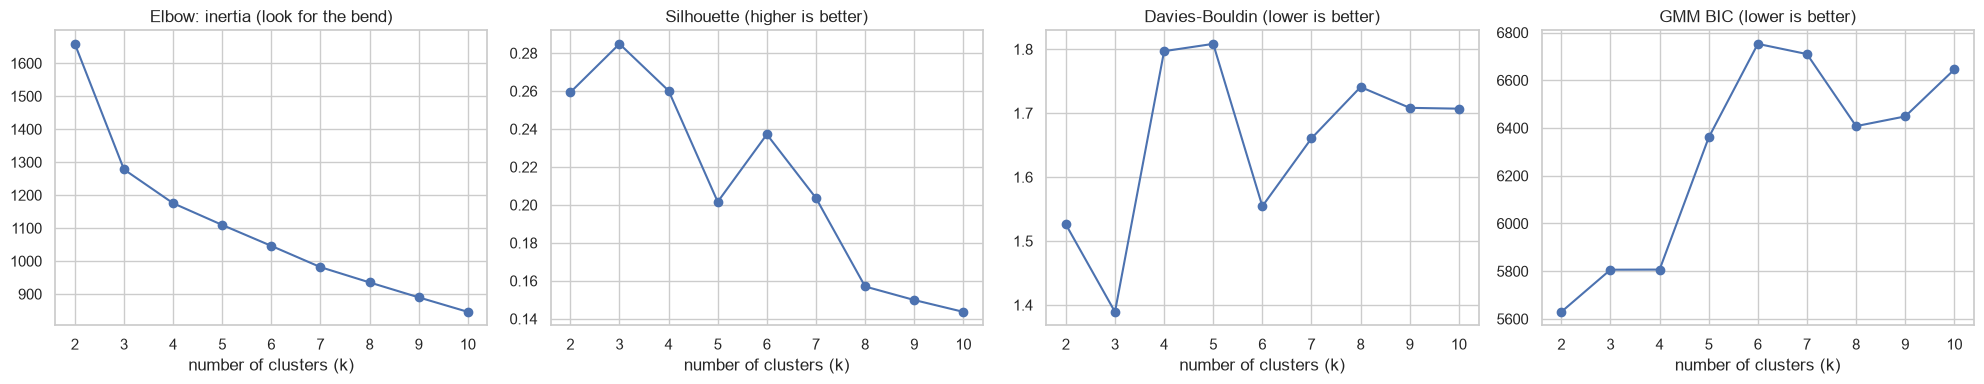

Best k by silhouette      : 3
Best k by Davies-Bouldin  : 3
Best k by BIC             : 2


In [5]:
k_values = list(range(2, 11))
inertia_list, sil_list, dbi_list, bic_list = [], [], [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(scaled)
    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(scaled, km.labels_))
    dbi_list.append(davies_bouldin_score(scaled, km.labels_))
    bic_list.append(GaussianMixture(k, n_init=3, random_state=SEED).fit(scaled).bic(scaled))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
curves = [(inertia_list, "Elbow: inertia (look for the bend)"),
          (sil_list, "Silhouette (higher is better)"),
          (dbi_list, "Davies-Bouldin (lower is better)"),
          (bic_list, "GMM BIC (lower is better)")]
for ax, (values, title) in zip(axes, curves):
    ax.plot(k_values, values, marker="o")
    ax.set_title(title)
    ax.set_xlabel("number of clusters (k)")
plt.tight_layout()
plt.show()

print("Best k by silhouette      :", k_values[int(np.argmax(sil_list))])
print("Best k by Davies-Bouldin  :", k_values[int(np.argmin(dbi_list))])
print("Best k by BIC             :", k_values[int(np.argmin(bic_list))])

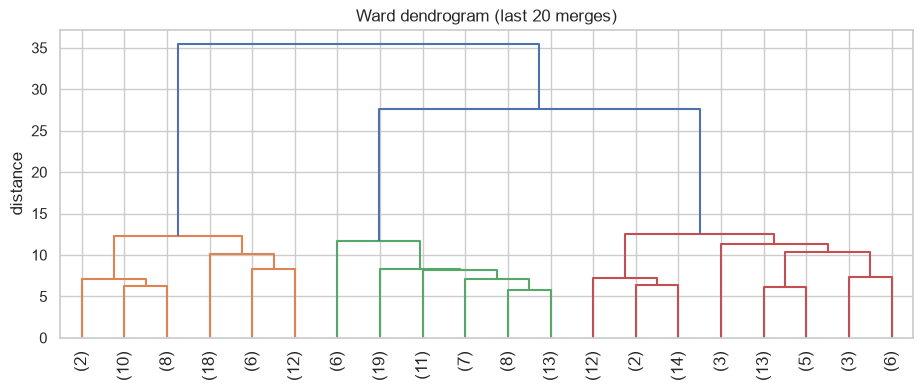

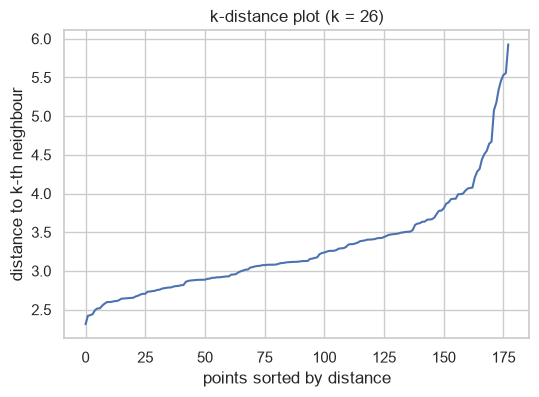

In [6]:
# Dendrogram: the long vertical lines show where big groups get merged
tree = linkage(scaled, method="ward")
plt.figure(figsize=(11, 4))
dendrogram(tree, truncate_mode="lastp", p=20, leaf_rotation=90,
           color_threshold=0.7 * tree[:, 2].max())
plt.title("Ward dendrogram (last 20 merges)")
plt.ylabel("distance")
plt.show()

# k-distance plot: the sharp bend suggests a value of eps for DBSCAN
min_pts = 2 * scaled.shape[1]
kth_dist = np.sort(NearestNeighbors(n_neighbors=min_pts).fit(scaled).kneighbors(scaled)[0][:, -1])
plt.figure(figsize=(6, 4))
plt.plot(kth_dist)
plt.title(f"k-distance plot (k = {min_pts})")
plt.xlabel("points sorted by distance")
plt.ylabel("distance to k-th neighbour")
plt.show()

Silhouette and Davies-Bouldin both choose **k = 3**. BIC chooses 2, because BIC punishes extra parameters heavily when there are only 178 points. The dendrogram shows three big branches, so I go with **k = 3**. This also makes sense because the wines come from 3 grape types.

### Step 5: Train the four algorithms

In [7]:
K = 3
results_labels = {}

results_labels["K-Means"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(scaled)
results_labels["Hierarchical (Ward)"] = AgglomerativeClustering(K, linkage="ward").fit_predict(scaled)
results_labels["Gaussian Mixture"] = GaussianMixture(K, covariance_type="full", n_init=5,
                                                     random_state=SEED).fit_predict(scaled)

# DBSCAN has no k, so I try a small grid of eps and min_samples.
# I only accept settings that find at least 2 clusters and keep more than half the points.
best_score, best_params = -1, None
for eps in np.arange(1.5, 4.1, 0.1):
    for min_samples in [3, 4, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(scaled)
        keep = lab != -1
        n_clusters = len(set(lab[keep]))
        if n_clusters >= 2 and keep.sum() > len(scaled) / 2:
            score = silhouette_score(scaled[keep], lab[keep])
            if score > best_score:
                best_score, best_params = score, (round(float(eps), 2), min_samples)

print("DBSCAN best settings (eps, min_samples):", best_params, "| silhouette:", round(best_score, 3))
results_labels["DBSCAN"] = DBSCAN(eps=best_params[0], min_samples=best_params[1]).fit_predict(scaled)

for name, lab in results_labels.items():
    ids, counts = np.unique(lab, return_counts=True)
    print(f"{name:22s} cluster sizes:", dict(zip(ids.tolist(), counts.tolist())))

DBSCAN best settings (eps, min_samples): (2.3, 10) | silhouette: 0.364
K-Means                cluster sizes: {0: 65, 1: 51, 2: 62}
Hierarchical (Ward)    cluster sizes: {0: 58, 1: 56, 2: 64}
Gaussian Mixture       cluster sizes: {0: 63, 1: 64, 2: 51}
DBSCAN                 cluster sizes: {-1: 64, 0: 84, 1: 30}


### Step 6: Measure the quality
For DBSCAN, noise points (label -1) are left out when calculating the internal scores, because they do not belong to any cluster.

In [8]:
rows = []
for name, lab in results_labels.items():
    keep = lab != -1
    n_clusters = len(set(lab[keep]))
    row = {"Algorithm": name, "Clusters": n_clusters, "Noise points": int((~keep).sum())}
    row["Silhouette (higher)"] = silhouette_score(scaled[keep], lab[keep])
    row["Davies-Bouldin (lower)"] = davies_bouldin_score(scaled[keep], lab[keep])
    row["Calinski-Harabasz (higher)"] = calinski_harabasz_score(scaled[keep], lab[keep])
    row["ARI vs real types (higher)"] = adjusted_rand_score(grape_type, lab)
    rows.append(row)

score_table = pd.DataFrame(rows).set_index("Algorithm").round(3)
score_table

,Clusters,Noise points,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),ARI vs real types (higher)
Algorithm,,,,,,
K-Means,3,0,0.285,1.389,70.940,0.897
Hierarchical (Ward),3,0,0.277,1.419,67.647,0.790
Gaussian Mixture,3,0,0.284,1.394,70.688,0.880
DBSCAN,2,64,0.364,1.048,64.741,0.282


### Step 7: Look at the clusters

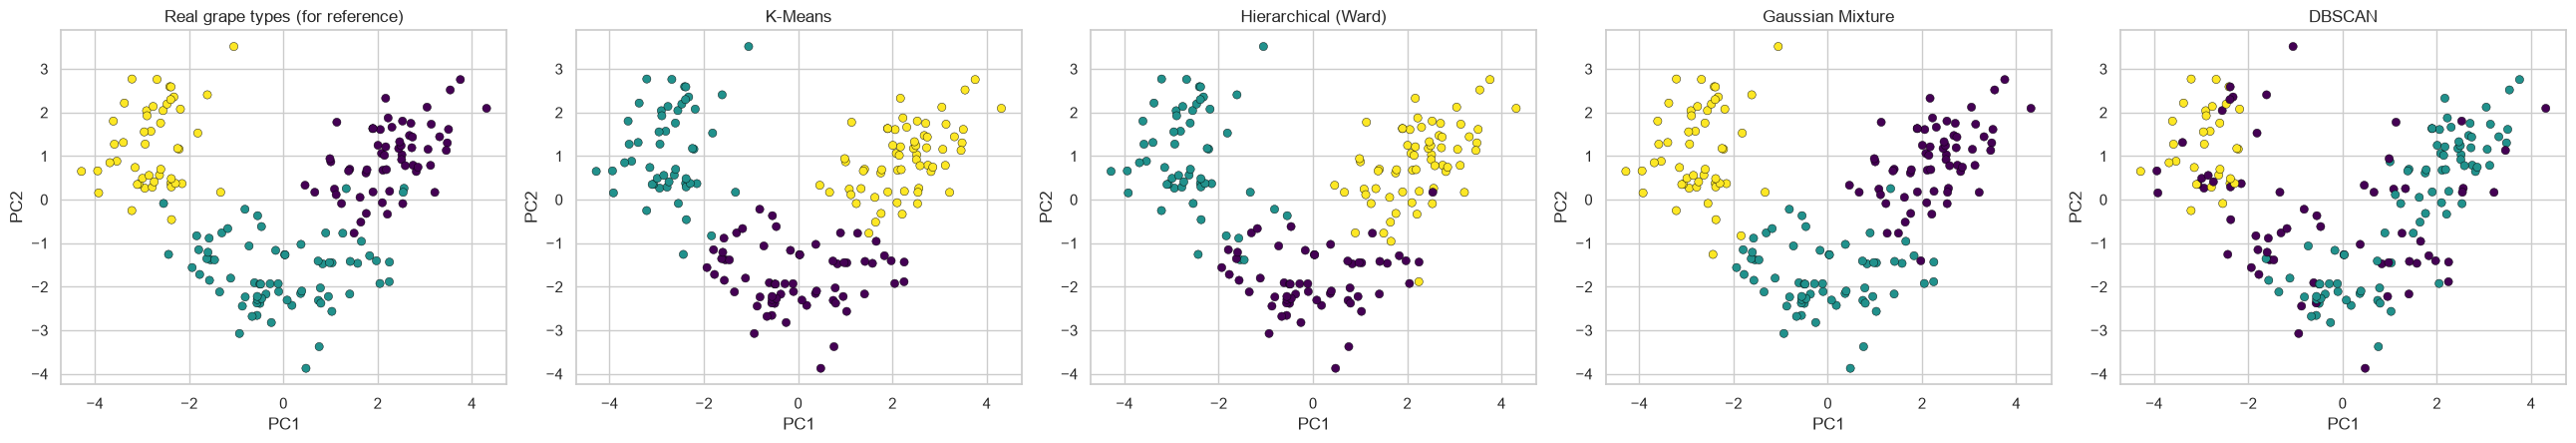

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.6))
panels = [("Real grape types (for reference)", grape_type)] + list(results_labels.items())
for ax, (title, lab) in zip(axes, panels):
    ax.scatter(plot_xy[:, 0], plot_xy[:, 1], c=lab, cmap="viridis", s=35,
               edgecolor="black", linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

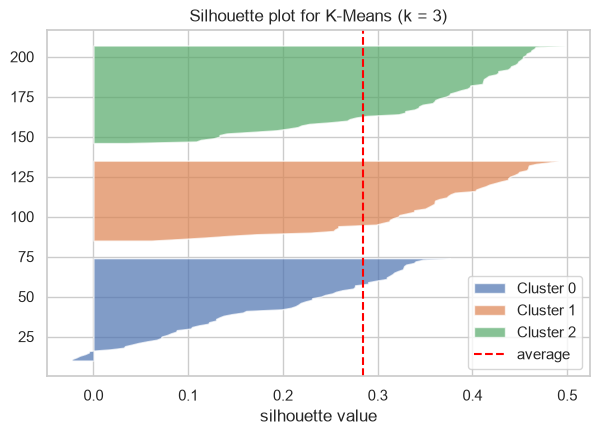

In [10]:
# Silhouette plot for K-Means: a wide bar means a point fits its cluster well
km_lab = results_labels["K-Means"]
sample_sil = silhouette_samples(scaled, km_lab)
fig, ax = plt.subplots(figsize=(7, 4.5))
start = 10
for c in range(K):
    vals = np.sort(sample_sil[km_lab == c])
    ax.fill_betweenx(np.arange(start, start + len(vals)), 0, vals, alpha=0.7, label=f"Cluster {c}")
    start += len(vals) + 10
ax.axvline(sample_sil.mean(), color="red", linestyle="--", label="average")
ax.set_title("Silhouette plot for K-Means (k = 3)")
ax.set_xlabel("silhouette value")
ax.legend()
plt.show()

### Step 8: Understand what each cluster means

cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


K-Means cluster,0,1,2
Real grape type,,,
0,0,0,59
1,65,3,3
2,0,48,0


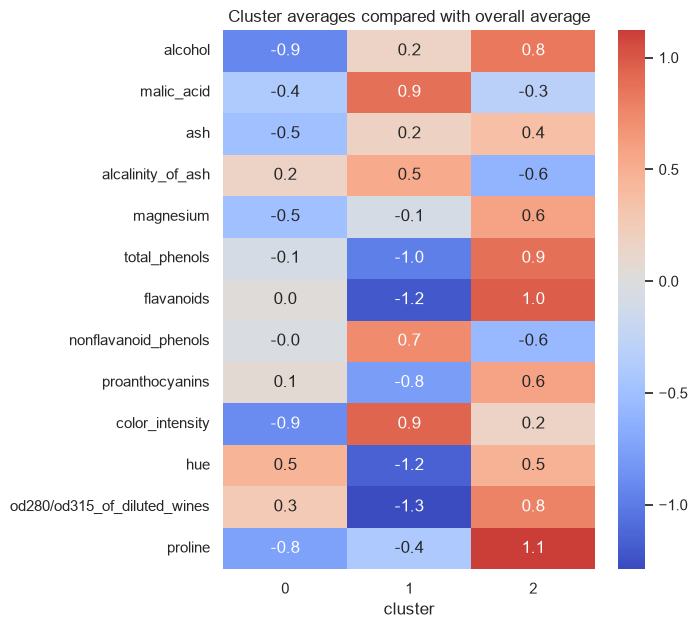

In [11]:
profile = data.copy()
profile["cluster"] = results_labels["K-Means"]
cluster_means = profile.groupby("cluster").mean()
display(cluster_means.round(2).T)

display(pd.crosstab(grape_type, results_labels["K-Means"],
                    rownames=["Real grape type"], colnames=["K-Means cluster"]))

# how far each cluster average is from the overall average (in standard deviations)
distance_from_avg = ((cluster_means - data.mean()) / data.std()).T
plt.figure(figsize=(6, 7))
sns.heatmap(distance_from_avg, cmap="coolwarm", center=0, annot=True, fmt=".1f")
plt.title("Cluster averages compared with overall average")
plt.show()

### Step 9: Extra experiment - does scaling really matter?
I run K-Means with k = 3 on three versions of the data: raw, scaled, and scaled with PCA (keeping 90% of the information).

In [12]:
versions = {
    "Raw (not scaled)": data.values,
    "Scaled": scaled,
    "Scaled + PCA (90% info)": PCA(n_components=0.90, random_state=SEED).fit_transform(scaled),
}
rows = []
for name, X_version in versions.items():
    lab = KMeans(3, n_init=10, random_state=SEED).fit_predict(X_version)
    rows.append({"Data version": name,
                 "Features": X_version.shape[1],
                 "Silhouette": silhouette_score(X_version, lab),
                 "Davies-Bouldin": davies_bouldin_score(X_version, lab),
                 "ARI": adjusted_rand_score(grape_type, lab)})
pd.DataFrame(rows).set_index("Data version").round(3)

,Features,Silhouette,Davies-Bouldin,ARI
Data version,,,,
Raw (not scaled),13,0.571,0.534,0.371
Scaled,13,0.285,1.389,0.897
Scaled + PCA (90% info),8,0.315,1.267,0.897


## Result

In [13]:
display(score_table)
print("Best silhouette score :", score_table["Silhouette (higher)"].idxmax())
print("Best ARI              :", score_table["ARI vs real types (higher)"].idxmax())

,Clusters,Noise points,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher),ARI vs real types (higher)
Algorithm,,,,,,
K-Means,3,0,0.285,1.389,70.940,0.897
Hierarchical (Ward),3,0,0.277,1.419,67.647,0.790
Gaussian Mixture,3,0,0.284,1.394,70.688,0.880
DBSCAN,2,64,0.364,1.048,64.741,0.282


Best silhouette score : DBSCAN
Best ARI              : K-Means


### What I observed
- **Number of clusters:** silhouette and Davies-Bouldin both gave k = 3. BIC gave k = 2, so the methods did not fully agree. I chose k = 3 because two methods and the dendrogram supported it.
- **K-Means** matched the real grape types best (ARI = 0.897, silhouette 0.285, Davies-Bouldin 1.389). **Gaussian Mixture** was almost the same (ARI = 0.880). **Ward hierarchical** was a little weaker (ARI = 0.790).
- **DBSCAN** has the best internal scores (silhouette 0.364, Davies-Bouldin 1.048), but this is misleading. It marked 64 out of 178 wines (36%) as noise and found only 2 clusters, so its ARI is just 0.282. Its scores cannot be compared fairly with the others because they ignore the noise points.
- **Scaling matters a lot:** K-Means on raw data got a higher silhouette (0.571) but a much lower ARI (0.371). Large values like *proline* took over the distance, so it made neat-looking groups that do not match the real wine types. After scaling, ARI went up to 0.897. This shows that one metric alone can fool us.
- **Using PCA** to keep 90% of the information (8 features) gave the same ARI (0.897) and a slightly better silhouette (0.315).
- **What the clusters mean:** one cluster has high proline, alcohol and flavanoids; another has high colour intensity but low flavanoids and hue; the third has low alcohol and low colour intensity.
- Silhouette scores near 0.28 mean the clusters are fair but overlap a little. They are not perfectly separated.

## Conclusion
In this experiment I applied K-Means, Hierarchical clustering, DBSCAN and Gaussian Mixture on the Wine dataset after scaling the features. All four were checked using Silhouette, Davies-Bouldin, Calinski-Harabasz, ARI and plots.

**K-Means with k = 3 was the best choice for this data.** It gave the highest ARI (0.897), balanced clusters that are easy to explain, and it runs fast. Gaussian Mixture was very close (ARI 0.880) and also gives probabilities, which is useful if a wine sits between two groups. Ward clustering was slightly worse, but its dendrogram helped confirm that 3 clusters is reasonable. DBSCAN did not suit this data: it threw away 36% of the points as noise and matched the real types poorly, because the density of points is not the same everywhere in 13 dimensions.

**Main learnings**
1. Always scale the features before using distance-based clustering.
2. Never trust only one metric. The raw-data model had a better silhouette score but was clearly worse.

**Limitations:** the dataset is small (178 wines) and comes from one region. The silhouette scores are only moderate. The 2-D PCA plot shows just 55% of the information. BIC and silhouette did not agree on k.

**Future work:** try spectral clustering or HDBSCAN, do feature selection, and test how stable the clusters are by repeating the clustering on random samples of the data.

**Ethical and social points:** wine data has no personal information, so there is no privacy issue here. But if the same method is used on people's data (for example customers or patients), clusters can become unfair, for instance in prices, loans or advertising. In such cases we should check the groups for bias, get consent, protect privacy, and use clustering only as a help for decisions, not as the final answer. In this work the real labels were never used for training, only for checking, so there is no data leakage.

**Self reflection:** while doing this I learned that preparing the data and choosing the right metric matter as much as choosing the algorithm. I want to learn more about how to test cluster stability and about density-based methods for data with many features.